# Ninapro DB3 sEMG: EDA (A–H) + Related Work


## 0. Setup & Mount Drive

In [1]:
!pip install -q umap-learn

import os, re, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

drive.mount('/content/drive')
DRIVE_FOLDER = '/content/drive/MyDrive/Ninapro_DB3'
LOCAL_DIR = '/content/Ninapro_DB3'
os.makedirs(LOCAL_DIR, exist_ok=True)
print('Local directory:', LOCAL_DIR)

Mounted at /content/drive
Local directory: /content/Ninapro_DB3


## 1. Extract & Clean Zip Files

In [2]:
zip_files = sorted(f for f in os.listdir(DRIVE_FOLDER) if f.endswith('.zip'))
failed_zips = []
for zf in zip_files:
    zip_path = os.path.join(DRIVE_FOLDER, zf)
    r = subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        failed_zips.append(zf)
        print(f'[WARNING] {zf}: {r.stderr.strip()[:200]}')

# Flatten sub-folders, delete macOS '._' files
for root, dirs, files in os.walk(LOCAL_DIR):
    for f in files:
        src = os.path.join(root, f)
        if f.startswith('._'):
            os.remove(src)
        elif f.endswith('.mat') and root != LOCAL_DIR:
            shutil.move(src, os.path.join(LOCAL_DIR, f))
shutil.rmtree(os.path.join(LOCAL_DIR, '__MACOSX'), ignore_errors=True)

mat_count = len([f for f in os.listdir(LOCAL_DIR) if f.endswith('.mat')])
print(f'Extraction complete: {mat_count} .mat files. Zips with errors: {failed_zips or "none"}')

[WARNING] s3_0.zip: error:  invalid compressed data to inflate /content/Ninapro_DB3/DB3_s3/S3_E1_A1.mat
Extraction complete: 33 .mat files. Zips with errors: ['s3_0.zip']


## 2. Load sEMG & Extract Window Features (per file, in mV)
**Fixes:** windows never cross file/subject boundaries; signal converted V→mV; ZC/SSC threshold is relative to each file's channel std (the old absolute `0.01` made ZC/SSC all zeros).

In [3]:
WIN, STEP = 300, 150            # 150 ms window, 50% overlap at 2 kHz
FEATURE_TYPES = ['MAV', 'RMS', 'VAR', 'WL', 'ZC', 'SSC']
THR_FACTOR = 0.1                # ZC/SSC threshold = 0.1 * channel std (tunable)

# DB3 exercises: E1 = gestures 1-17, E2 = 18-40, E3 = 41-49.
# If the printed label ranges below show E2/E3 starting at 1, set {2: 17, 3: 40}.
EX_OFFSET = {1: 0, 2: 0, 3: 0}

def window_features(emg, lbl):
    emg = emg.astype(np.float64) * 1000.0                  # V -> mV
    thr = THR_FACTOR * emg.std(axis=0)[None, :, None]
    W = sliding_window_view(emg, WIN, axis=0)[::STEP]      # (n_win, ch, WIN)
    L = sliding_window_view(lbl, WIN)[::STEP]              # (n_win, WIN)
    ok = (L == L[:, :1]).all(axis=1)                       # uniform label only
    W, y = W[ok], L[ok, 0]
    d = np.diff(W, axis=-1)
    mav = np.abs(W).mean(-1)
    rms = np.sqrt((W ** 2).mean(-1))
    var = W.var(-1)
    wl  = np.abs(d).sum(-1)
    zc  = ((W[..., :-1] * W[..., 1:] < 0) & (np.abs(d) >= thr)).sum(-1)
    ssc = ((d[..., :-1] * d[..., 1:] < 0) &
           (np.abs(d[..., :-1] - d[..., 1:]) >= thr)).sum(-1)
    return np.hstack([mav, rms, var, wl, zc, ssc]), y

mat_files = sorted(os.path.join(LOCAL_DIR, f) for f in os.listdir(LOCAL_DIR)
                   if f.endswith('.mat') and not f.startswith('._'))

X_parts, y_parts, s_parts, ex_parts = [], [], [], []
corrupted, raw_points, n_channels = [], 0, None
label_ranges = {}

for fp in mat_files:
    base = os.path.basename(fp)
    m = re.match(r'S(\d+)_E(\d+)', base)
    sid, ex = int(m.group(1)), int(m.group(2))
    try:
        mat = sio.loadmat(fp)
        emg, lbl = mat['emg'], mat['restimulus'].ravel().astype(np.int64)
        lbl = np.where(lbl > 0, lbl + EX_OFFSET.get(ex, 0), 0)
        Xf, yf = window_features(emg, lbl)
    except Exception as e:
        corrupted.append((base, str(e)[:120]))
        continue
    n_channels = emg.shape[1]
    raw_points += len(emg)
    X_parts.append(Xf); y_parts.append(yf)
    s_parts.append(np.full(len(yf), sid)); ex_parts.append(np.full(len(yf), ex))
    nz = np.unique(yf[yf > 0])
    if len(nz):
        lo, hi = label_ranges.get(ex, (10**9, -1))
        label_ranges[ex] = (min(lo, nz.min()), max(hi, nz.max()))

if corrupted:
    print('[WARNING] Corrupted files (re-download these zips):')
    for f, e in corrupted: print(f'  - {f}: {e}')

names = [f'{f}_Ch{c}' for f in FEATURE_TYPES for c in range(1, n_channels + 1)]
df = pd.DataFrame(np.vstack(X_parts), columns=names)
df['Gesture_Label'] = np.concatenate(y_parts)
df['Subject_ID']    = np.concatenate(s_parts)
df['Exercise']      = np.concatenate(ex_parts)

print(f'\nLoaded {len(X_parts)}/{len(mat_files)} files | raw points: {raw_points:,}')
print(f'Feature dataset: {df.shape} | subjects: {sorted(df.Subject_ID.unique())}')
print('Label range per exercise:', label_ranges)
print('\nZC/SSC sanity check (must NOT be all zero):')
print(df[[c for c in df if c.startswith(("ZC", "SSC"))]].mean().round(2).head(6).to_string())

[WARNING] Corrupted files (re-download these zips):
  - S3_E1_A1.mat: Error -3 while decompressing data: invalid code lengths set

Loaded 32/33 files | raw points: 53,103,168
Feature dataset: (341962, 75) | subjects: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
Label range per exercise: {1: (np.int64(1), np.int64(17)), 2: (np.int64(18), np.int64(40)), 3: (np.int64(41), np.int64(49))}

ZC/SSC sanity check (must NOT be all zero):
ZC_Ch1    34.66
ZC_Ch2    38.10
ZC_Ch3    36.86
ZC_Ch4    40.88
ZC_Ch5    42.09
ZC_Ch6    41.62


## A. Dataset Summary Table

In [4]:
META = ['Gesture_Label', 'Subject_ID', 'Exercise']
feat_cols = [c for c in df.columns if c not in META]

class_counts = df['Gesture_Label'].value_counts().sort_index()
active_counts = class_counts.drop(0, errors='ignore')
n_dup  = int(df.duplicated().sum())
n_miss = int(df.isnull().sum().sum())

summary = pd.DataFrame({
    'Attribute': ['Name', 'Source', 'Area', 'Samples (windows)', 'Raw signal points',
                  'Classes', 'Features (count / type)', 'Subjects / hosts',
                  'Class balance (all / active-only)', 'Missing values', 'Duplicate rows'],
    'Value': [
        'Ninapro DB3',
        'Ninapro project (ninapro.hevs.ch), Atzori et al. 2014',
        'Biomedical signals: sEMG hand-gesture recognition (transradial amputees)',
        f'{len(df):,} (window {WIN} samples = {WIN/2:.0f} ms @2 kHz, 50% overlap)',
        f'{raw_points:,}',
        f'{df.Gesture_Label.nunique()} (rest + {df.Gesture_Label.nunique()-1} gestures)',
        f'{len(feat_cols)} numeric time-domain ({", ".join(FEATURE_TYPES)} x {n_channels} channels)',
        f'{df.Subject_ID.nunique()} amputee subjects, {len(X_parts)} files loaded',
        f'{class_counts.max()/class_counts.min():.1f}:1 / {active_counts.max()/active_counts.min():.1f}:1',
        f'{n_miss} ({n_miss/df[feat_cols].size*100:.2f}%)',
        f'{n_dup} ({n_dup/len(df)*100:.2f}%)'],
})
pd.set_option('display.max_colwidth', 120)
print('=== A: DATASET SUMMARY ===')
display(summary)
print('\nWindows per subject:')
display(df.groupby('Subject_ID').size().rename('windows').to_frame().T)

=== A: DATASET SUMMARY ===


,Attribute,Value
0,Name,Ninapro DB3
1,Source,"Ninapro project (ninapro.hevs.ch), Atzori et al. 2014"
2,Area,Biomedical signals: sEMG hand-gesture recognition (transradial amputees)
3,Samples (windows),"341,962 (window 300 samples = 150 ms @2 kHz, 50% overlap)"
4,Raw signal points,"53,103,168"
5,Classes,50 (rest + 49 gestures)
6,Features (count / type),"72 numeric time-domain (MAV, RMS, VAR, WL, ZC, SSC x 12 channels)"
7,Subjects / hosts,"11 amputee subjects, 32 files loaded"
8,Class balance (all / active-only),37.5:1 / 1.5:1
9,Missing values,0 (0.00%)



Windows per subject:


Subject_ID,1,2,3,4,5,6,7,8,9,10,11
windows,25675,33153,21553,33657,33681,33635,32946,32955,32962,28594,33151


## B. Descriptive Statistics (all features)

In [5]:
rows = []
for col in feat_cols:
    x = df[col].values
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    iqr = q3 - q1
    n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
    rows.append(dict(Feature=col, Type=col.split('_')[0], Mean=x.mean(), Median=med, Std=x.std(),
                     Min=x.min(), Q25=q1, Q75=q3, Max=x.max(),
                     Skewness=skew(x), Kurtosis=kurtosis(x),
                     Outliers=n_out, Outliers_pct=100 * n_out / len(x)))
df_stats = pd.DataFrame(rows)
df_stats.to_csv('/content/feature_statistics.csv', index=False)

print('=== B: STATISTICS BY FEATURE TYPE (median across channels; units: mV-based) ===')
with pd.option_context('display.float_format', '{:.3e}'.format, 'display.width', 250):
    display(df_stats.groupby('Type', sort=False)[['Mean', 'Median', 'Std', 'Min', 'Q25', 'Q75', 'Max',
                                                  'Skewness', 'Kurtosis', 'Outliers_pct']].median())
    print('\nFull per-feature table (first 12 rows; all 72 saved to /content/feature_statistics.csv):')
    display(df_stats.head(12))

=== B: STATISTICS BY FEATURE TYPE (median across channels; units: mV-based) ===


,Mean,Median,Std,Min,Q25,Q75,Max,Skewness,Kurtosis,Outliers_pct
Type,,,,,,,,,,
MAV,7.369e-03,2.840e-03,2.600e-02,0.000e+00,1.984e-03,5.817e-03,3.780e+00,6.873e+01,5.520e+03,1.111e+01
RMS,1.018e-02,3.687e-03,3.577e-02,0.000e+00,2.494e-03,8.130e-03,4.084e+00,5.432e+01,4.403e+03,1.111e+01
VAR,1.350e-03,1.358e-05,8.112e-02,0.000e+00,6.197e-06,6.717e-05,1.657e+01,9.864e+01,1.075e+04,1.554e+01
WL,1.010e+00,4.231e-01,1.602e+00,0.000e+00,3.080e-01,8.665e-01,1.123e+02,1.083e+01,1.442e+02,1.159e+01
ZC,3.820e+01,4.000e+01,1.576e+01,0.000e+00,2.800e+01,4.900e+01,8.500e+01,-5.322e-01,-3.413e-01,8.480e-03
SSC,7.246e+01,8.150e+01,2.863e+01,0.000e+00,5.450e+01,9.450e+01,1.305e+02,-7.982e-01,-4.720e-01,0.000e+00



Full per-feature table (first 12 rows; all 72 saved to /content/feature_statistics.csv):


,Feature,Type,Mean,Median,Std,Min,Q25,Q75,Max,Skewness,Kurtosis,Outliers,Outliers_pct
0,MAV_Ch1,MAV,9.055e-03,3.858e-03,2.283e-02,0.000e+00,2.026e-03,9.378e-03,4.033e+00,7.530e+01,9.616e+03,36843,1.077e+01
1,MAV_Ch2,MAV,7.069e-03,2.941e-03,1.159e-02,0.000e+00,2.047e-03,6.476e-03,2.259e-01,4.522e+00,2.835e+01,40766,1.192e+01
2,MAV_Ch3,MAV,7.669e-03,2.634e-03,1.440e-02,0.000e+00,1.862e-03,5.158e-03,7.690e-01,5.265e+00,7.892e+01,53790,1.573e+01
3,MAV_Ch4,MAV,4.459e-03,2.475e-03,3.452e-02,0.000e+00,1.797e-03,3.786e-03,3.735e+00,7.762e+01,6.547e+03,38403,1.123e+01
4,MAV_Ch5,MAV,4.323e-03,2.705e-03,7.673e-03,0.000e+00,1.942e-03,4.029e-03,1.752e-01,9.890e+00,1.245e+02,33634,9.836e+00
5,MAV_Ch6,MAV,5.939e-03,2.600e-03,2.836e-02,0.000e+00,1.849e-03,4.946e-03,3.825e+00,7.488e+01,7.540e+03,37556,1.098e+01
6,MAV_Ch7,MAV,3.382e-02,3.154e-03,2.154e-01,0.000e+00,2.052e-03,6.546e-03,4.655e+00,1.111e+01,1.432e+02,48741,1.425e+01
7,MAV_Ch8,MAV,8.850e-03,3.721e-03,4.651e-02,2.594e-16,2.146e-03,7.978e-03,4.594e+00,6.257e+01,4.493e+03,41800,1.222e+01
8,MAV_Ch9,MAV,4.483e-03,2.430e-03,3.889e-02,0.000e+00,1.704e-03,4.185e-03,4.791e+00,8.294e+01,7.722e+03,35539,1.039e+01
9,MAV_Ch10,MAV,7.905e-03,3.093e-03,2.364e-02,0.000e+00,1.652e-03,7.148e-03,3.036e+00,4.792e+01,4.333e+03,39552,1.157e+01


## C. Data Quality

In [6]:
# Rank once, then Pearson on ranks = Spearman (fast, robust to skew/outliers)
corr_sp = df[feat_cols].rank().corr()

missing_pct = df[feat_cols].isnull().mean().mean() * 100
dup_pct = df.duplicated().mean() * 100

# near-constant: zero std OR one value covers >99% of rows (scale-free test)
near_constant = [c for c in feat_cols
                 if df[c].std() == 0 or df[c].value_counts(normalize=True).iloc[0] > 0.99]

upper = corr_sp.abs().where(np.triu(np.ones(corr_sp.shape), 1).astype(bool))
pairs = [(r, c, round(v, 4)) for c in upper.columns
         for r, v in upper[c].items() if pd.notna(v) and v >= 0.95]

avg_out = df_stats.Outliers_pct.mean()
max_skew = df_stats.Skewness.abs().max()

quality = pd.DataFrame({
    'Check': ['Missing values', 'Duplicate rows', 'Near-constant features',
              'Highly correlated pairs (|rho| >= 0.95, Spearman)', 'Outliers (IQR rule, avg/feature)',
              'Skewness (max |skew|)'],
    'Result': [f'{missing_pct:.2f}%', f'{dup_pct:.2f}%',
               f'{len(near_constant)} {near_constant[:6]}', f'{len(pairs)}',
               f'{avg_out:.2f}%', f'{max_skew:.1f}'],
    'Effect on modeling': [
        'None needed' if missing_pct == 0 else 'Impute or drop before training',
        'None needed' if dup_pct == 0 else 'Drop; duplicates inflate test scores',
        'Remove: no information' if near_constant else 'None',
        'Redundant; hurts linear/NN conditioning, drop one of each pair or use PCA' if pairs else 'None',
        'sEMG bursts are real signal; prefer robust/quantile scaling over clipping',
        'Log or quantile-transform before distance-based models (SVM, kNN, t-SNE)']})
print('=== C: DATA QUALITY ===')
display(quality)
if pairs:
    print('\nFirst 8 redundant pairs:')
    for p in pairs[:8]: print(f'  {p[0]} <-> {p[1]}  rho={p[2]}')

=== C: DATA QUALITY ===


,Check,Result,Effect on modeling
0,Missing values,0.00%,None needed
1,Duplicate rows,0.00%,None needed
2,Near-constant features,0 [],None
3,"Highly correlated pairs (|rho| >= 0.95, Spearman)",60,"Redundant; hurts linear/NN conditioning, drop one of each pair or use PCA"
4,"Outliers (IQR rule, avg/feature)",8.79%,sEMG bursts are real signal; prefer robust/quantile scaling over clipping
5,Skewness (max |skew|),229.1,"Log or quantile-transform before distance-based models (SVM, kNN, t-SNE)"



First 8 redundant pairs:
  MAV_Ch1 <-> RMS_Ch1  rho=0.9931
  MAV_Ch2 <-> RMS_Ch2  rho=0.9949
  MAV_Ch3 <-> RMS_Ch3  rho=0.9968
  MAV_Ch4 <-> RMS_Ch4  rho=0.9965
  MAV_Ch5 <-> RMS_Ch5  rho=0.9945
  MAV_Ch6 <-> RMS_Ch6  rho=0.9968
  MAV_Ch7 <-> RMS_Ch7  rho=0.9958
  MAV_Ch8 <-> RMS_Ch8  rho=0.9962


## D. Class Balance

Classes: 50 | Majority: label 0 (128,847, 37.7%) | Minority: label 17 (3,433, 1.00%)
Imbalance ratio all classes: 37.5:1 | active gestures only: 1.5:1

Baseline predicting always label 0: accuracy = 37.7%, macro-F1 = 0.011


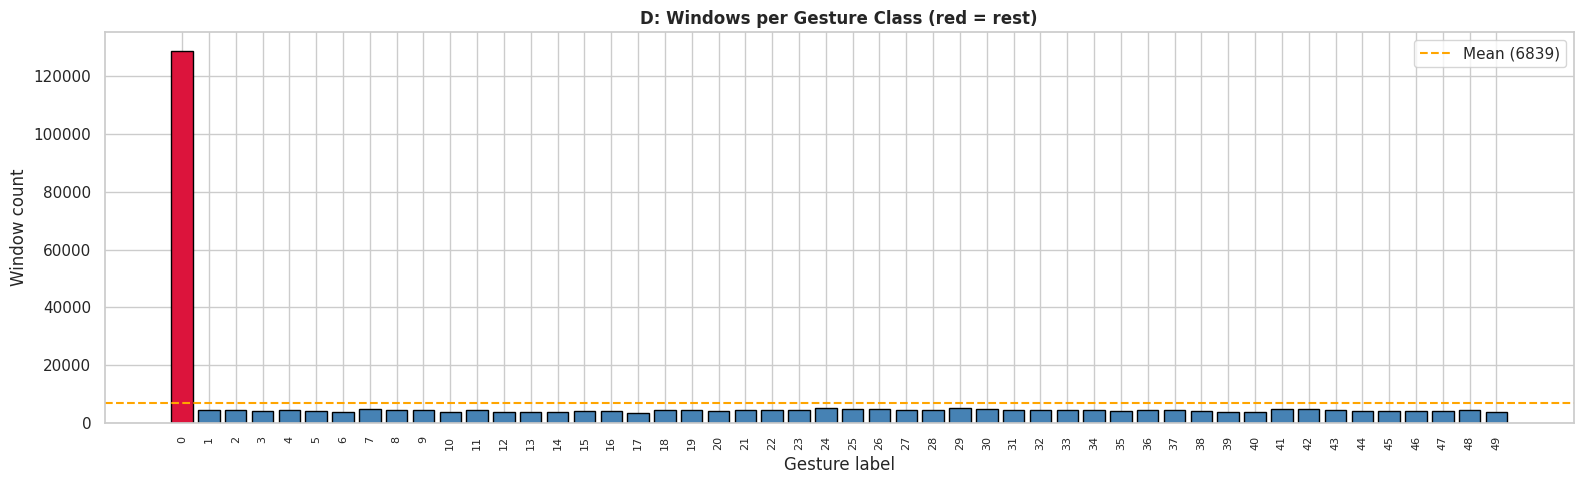


Effect on metrics: accuracy is inflated by the rest class; report macro-F1 / balanced accuracy, use class weights or balanced sampling, and stratify splits.


In [7]:
from sklearn.metrics import f1_score

pct = class_counts / len(df) * 100
print(f'Classes: {len(class_counts)} | Majority: label {class_counts.idxmax()} '
      f'({class_counts.max():,}, {pct.max():.1f}%) | Minority: label {class_counts.idxmin()} '
      f'({class_counts.min():,}, {pct.min():.2f}%)')
print(f'Imbalance ratio all classes: {class_counts.max()/class_counts.min():.1f}:1 | '
      f'active gestures only: {active_counts.max()/active_counts.min():.1f}:1')

# What a "always predict majority" model scores
maj = class_counts.idxmax()
y_true = df.Gesture_Label.values
y_pred = np.full_like(y_true, maj)
print(f'\nBaseline predicting always label {maj}: accuracy = {(y_true==y_pred).mean()*100:.1f}%, '
      f'macro-F1 = {f1_score(y_true, y_pred, average="macro", zero_division=0):.3f}')

colors = ['crimson' if i == 0 else 'steelblue' for i in class_counts.index]
plt.figure(figsize=(16, 5))
plt.bar(class_counts.index.astype(str), class_counts.values, color=colors, edgecolor='black')
plt.axhline(class_counts.mean(), color='orange', ls='--', label=f'Mean ({class_counts.mean():.0f})')
plt.title('D: Windows per Gesture Class (red = rest)', fontweight='bold')
plt.xlabel('Gesture label'); plt.ylabel('Window count')
plt.xticks(rotation=90, fontsize=8); plt.legend(); plt.tight_layout(); plt.show()

print('\nEffect on metrics: accuracy is inflated by the rest class; report macro-F1 / balanced '
      'accuracy, use class weights or balanced sampling, and stratify splits.')

## E. Feature Distributions (histogram, box, violin)

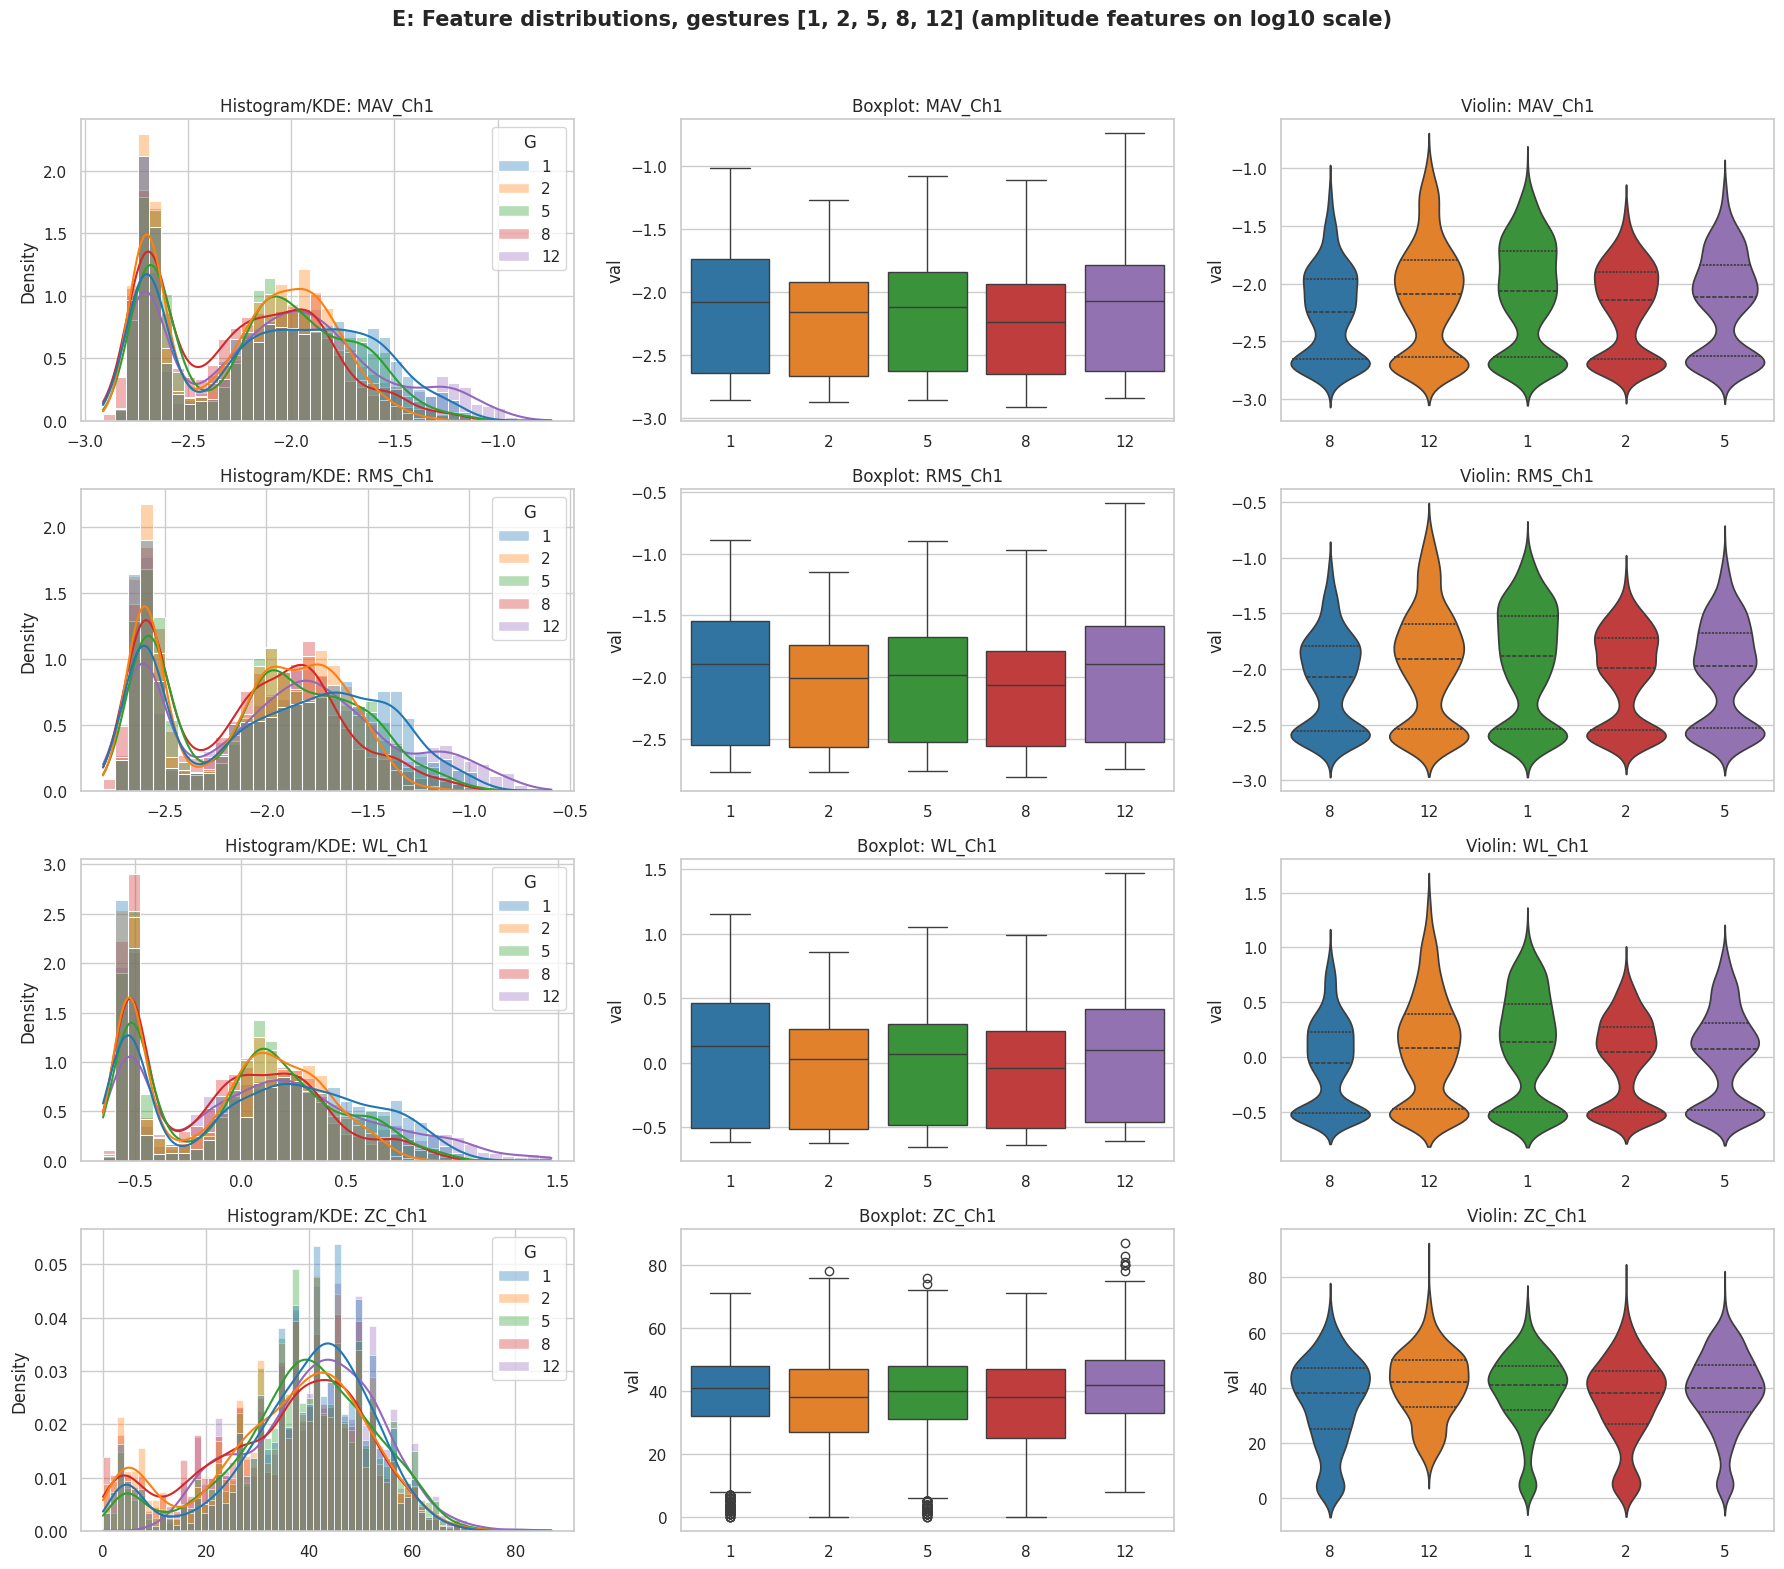

--- Do classes separate? (eta^2 = share of variance explained by gesture class) ---
MAV_Ch1    eta2 raw = 0.020 (weak) | after per-subject z-score = 0.030
RMS_Ch1    eta2 raw = 0.020 (weak) | after per-subject z-score = 0.036
WL_Ch1     eta2 raw = 0.021 (weak) | after per-subject z-score = 0.037
ZC_Ch1     eta2 raw = 0.022 (weak) | after per-subject z-score = 0.017
Rule of thumb: <0.06 weak, 0.06-0.14 moderate, >0.14 strong. Features with low eta^2 add little on their own; judge them jointly in section G. Compare raw vs per-subject values to see subject effects.


In [8]:
sample_classes = [1, 2, 5, 8, 12]
key_features = ['MAV_Ch1', 'RMS_Ch1', 'WL_Ch1', 'ZC_Ch1']
sub = df[df.Gesture_Label.isin(sample_classes)].copy()
sub['G'] = sub.Gesture_Label.astype(str)

def tf(series, f):   # log10 for continuous amplitude features, raw for counts
    return series if f.startswith(('ZC', 'SSC')) else np.log10(series + 1e-6)

def eta_sq(vals, groups):
    g = vals.groupby(groups)
    return float((g.count() * (g.mean() - vals.mean()) ** 2).sum() / ((vals - vals.mean()) ** 2).sum())

fig, axes = plt.subplots(len(key_features), 3, figsize=(18, 4 * len(key_features)))
fig.suptitle(f'E: Feature distributions, gestures {sample_classes} (amplitude features on log10 scale)',
             fontsize=15, fontweight='bold')
effects = []
for i, f in enumerate(key_features):
    d = pd.DataFrame({'val': tf(sub[f], f), 'G': sub.G, 'S': sub.Subject_ID})
    ok_kde = d.groupby('G')['val'].std().min() > 0
    sns.histplot(d, x='val', hue='G', kde=ok_kde, stat='density', common_norm=False,
                 palette='tab10', alpha=0.35, ax=axes[i, 0])
    sns.boxplot(d, x='G', y='val', hue='G', palette='tab10', legend=False, ax=axes[i, 1])
    dv = d.sample(frac=1, random_state=0).groupby('G').head(2000)
    sns.violinplot(dv, x='G', y='val', hue='G', palette='tab10', inner='quartile', legend=False,
                   ax=axes[i, 2])
    for j, t in enumerate(['Histogram/KDE', 'Boxplot', 'Violin']):
        axes[i, j].set_title(f'{t}: {f}'); axes[i, j].set_xlabel('')
    z = d.groupby('S')['val'].transform(lambda s: (s - s.mean()) / (s.std() + 1e-12))
    effects.append((f, eta_sq(d.val, d.G), eta_sq(z, d.G)))
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print('--- Do classes separate? (eta^2 = share of variance explained by gesture class) ---')
for f, e_raw, e_sub in effects:
    lvl = 'strong' if e_raw > 0.14 else 'moderate' if e_raw > 0.06 else 'weak'
    print(f'{f:10s} eta2 raw = {e_raw:.3f} ({lvl}) | after per-subject z-score = {e_sub:.3f}')
print('Rule of thumb: <0.06 weak, 0.06-0.14 moderate, >0.14 strong. Features with low eta^2 add little '
      'on their own; judge them jointly in section G. Compare raw vs per-subject values to see subject effects.')

## F. Correlation Heatmap & Redundant Features

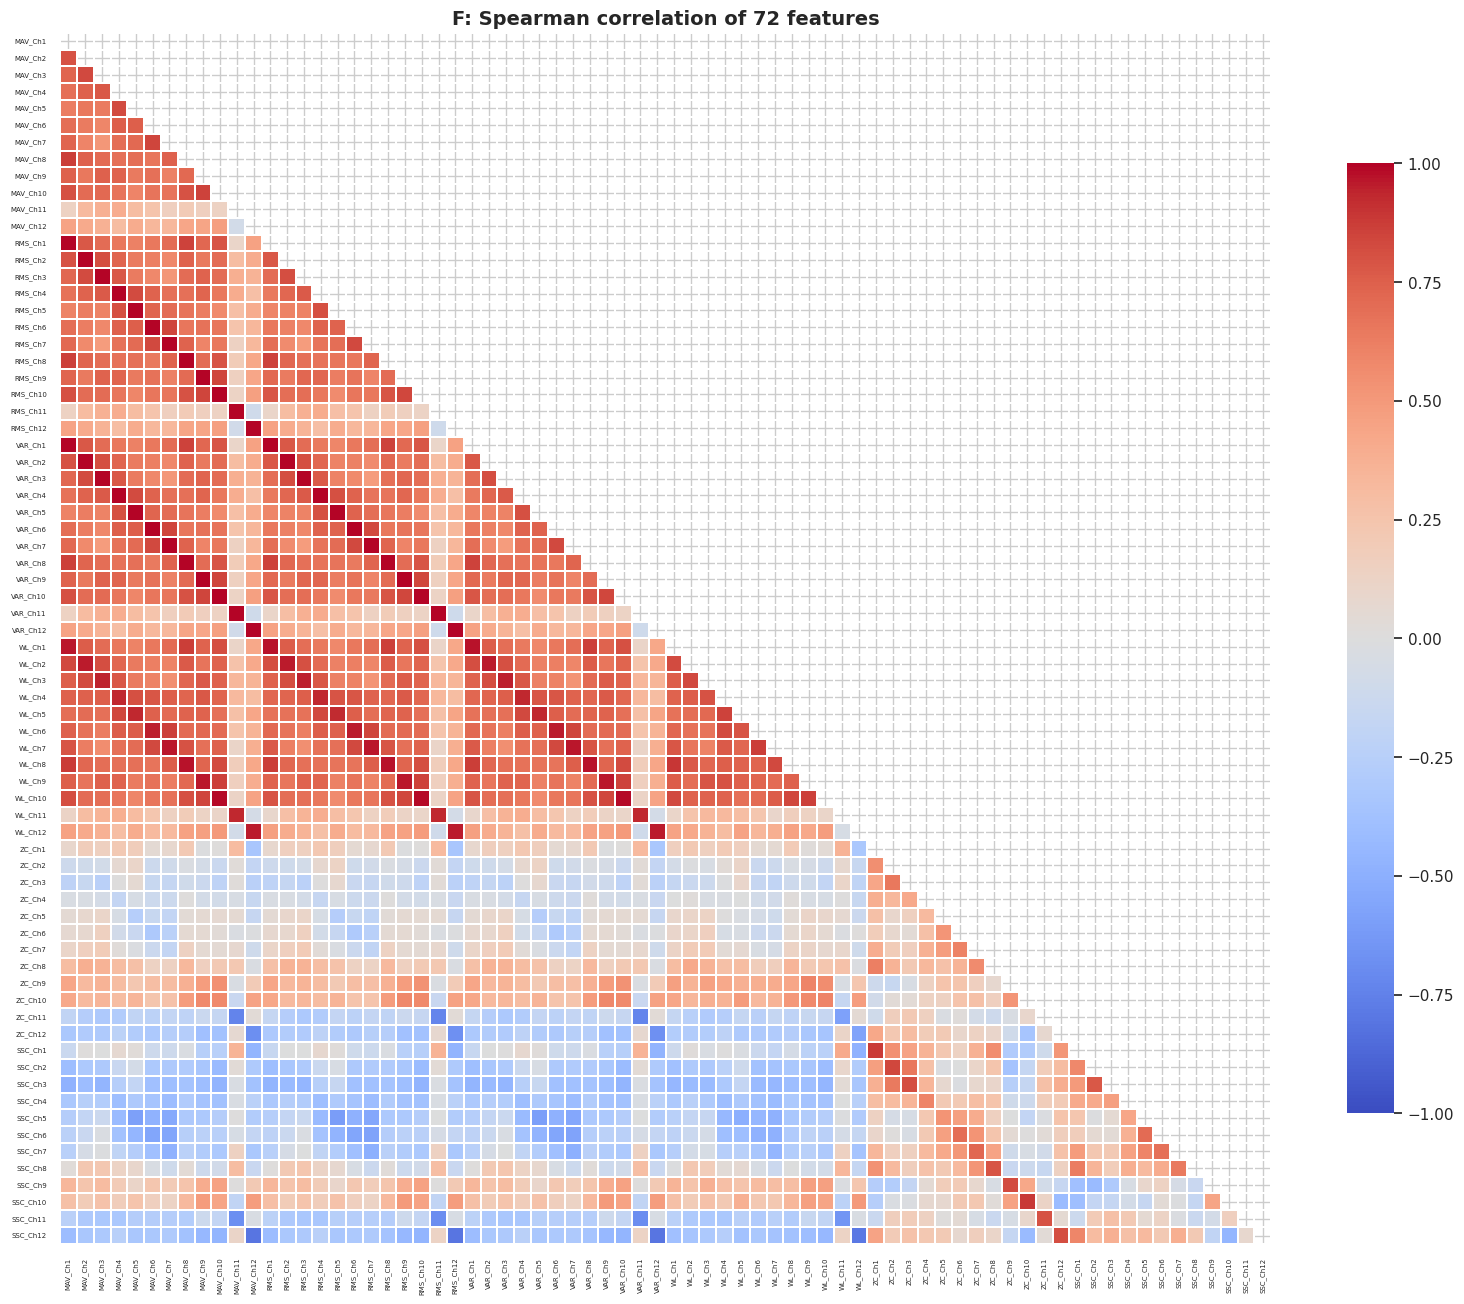

Redundant pairs (|rho| >= 0.95): 60


,Feature_1,Feature_2,abs_rho
0,MAV_Ch1,RMS_Ch1,0.9931
1,MAV_Ch2,RMS_Ch2,0.9949
2,MAV_Ch3,RMS_Ch3,0.9968
3,MAV_Ch4,RMS_Ch4,0.9965
4,MAV_Ch5,RMS_Ch5,0.9945
5,MAV_Ch6,RMS_Ch6,0.9968
6,MAV_Ch7,RMS_Ch7,0.9958
7,MAV_Ch8,RMS_Ch8,0.9962
8,MAV_Ch9,RMS_Ch9,0.9979
9,MAV_Ch10,RMS_Ch10,0.9978



Suggested drop list (32): ['RMS_Ch1', 'RMS_Ch10', 'RMS_Ch11', 'RMS_Ch12', 'RMS_Ch2', 'RMS_Ch3', 'RMS_Ch4', 'RMS_Ch5', 'RMS_Ch6', 'RMS_Ch7', 'RMS_Ch8', 'RMS_Ch9', 'VAR_Ch1', 'VAR_Ch10', 'VAR_Ch11', 'VAR_Ch12', 'VAR_Ch2', 'VAR_Ch3', 'VAR_Ch4', 'VAR_Ch5', 'VAR_Ch6', 'VAR_Ch7', 'VAR_Ch8', 'VAR_Ch9', 'WL_Ch1', 'WL_Ch10', 'WL_Ch12', 'WL_Ch2', 'WL_Ch6', 'WL_Ch7', 'WL_Ch8', 'WL_Ch9']
Reduced feature set: 40 of 72 features


In [9]:
plt.figure(figsize=(16, 14))
sns.heatmap(corr_sp, mask=np.triu(np.ones_like(corr_sp, dtype=bool)), cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.2,
            xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.7})
plt.xticks(fontsize=5); plt.yticks(fontsize=5)
plt.title(f'F: Spearman correlation of {len(feat_cols)} features', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

df_redundant = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'abs_rho'])
print(f'Redundant pairs (|rho| >= 0.95): {len(df_redundant)}')
display(df_redundant.head(15))

# Keep the earlier-listed feature of each pair (MAV kept over RMS), drop the later one
drop_corr = sorted({c for c in upper.columns if (upper[c] >= 0.95).any()})
drop_list = sorted(set(drop_corr) | set(near_constant))
feat_reduced = [c for c in feat_cols if c not in drop_list]
print(f'\nSuggested drop list ({len(drop_list)}): {drop_list}')
print(f'Reduced feature set: {len(feat_reduced)} of {len(feat_cols)} features')

## G. 2D Projection: PCA / t-SNE / UMAP

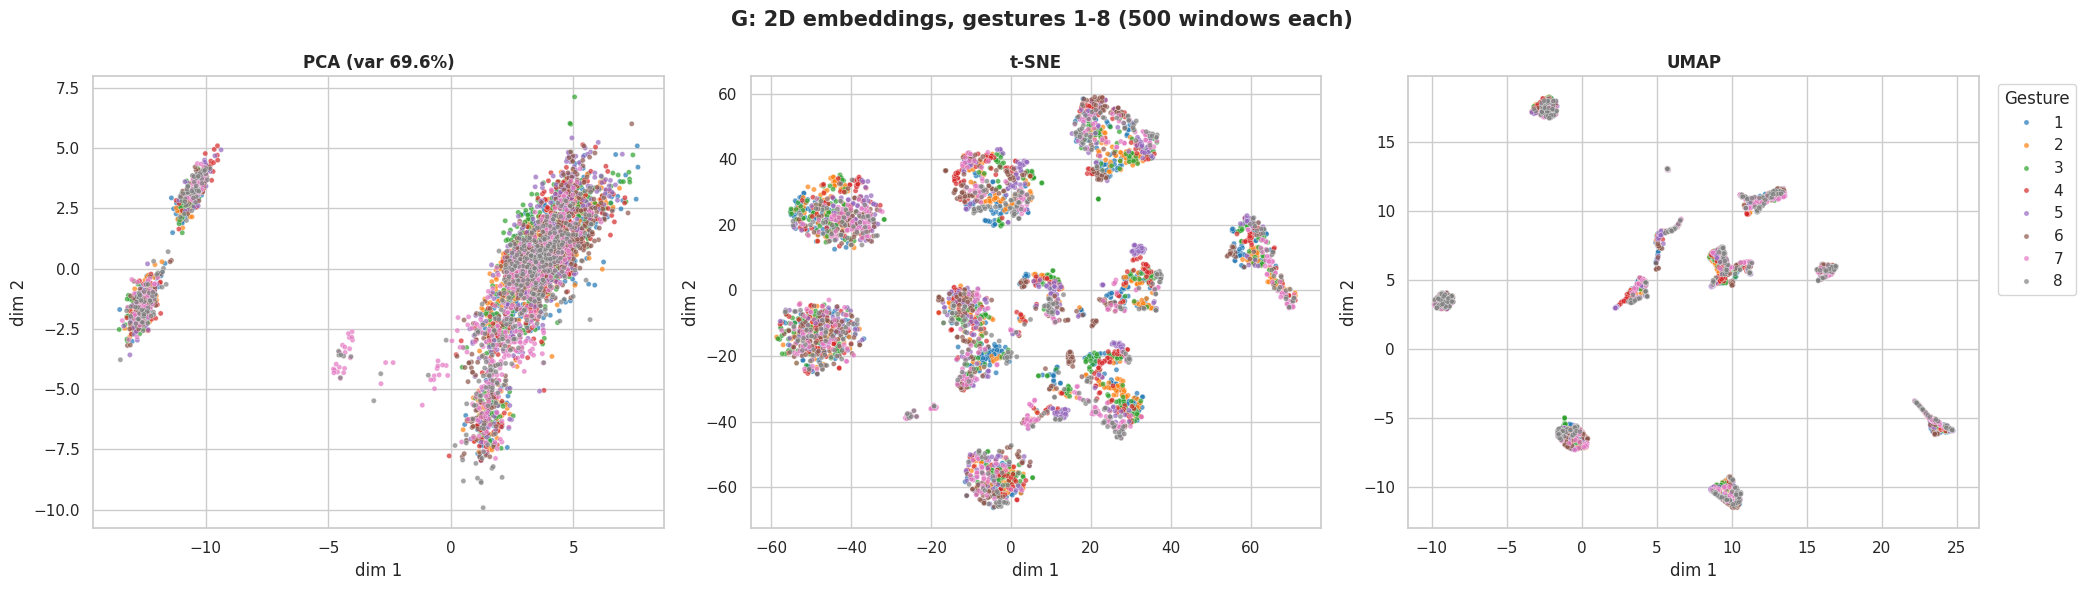

--- Do classes separate? (silhouette: -1..1; >0.25 clear, 0.05-0.25 weak, <0.05 overlapping) ---
PCA (var 69.6%)        gesture silhouette = -0.058 (overlapping) | subject silhouette = +0.136
t-SNE                  gesture silhouette = -0.053 (overlapping) | subject silhouette = +0.590
UMAP                   gesture silhouette = -0.030 (overlapping) | subject silhouette = +0.783
A higher subject than gesture silhouette means subject identity dominates the structure: use subject-wise splits and per-subject normalisation.


In [10]:
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import silhouette_score

vis_classes = [1, 2, 3, 4, 5, 6, 7, 8]
_pool = df[df.Gesture_Label.isin(vis_classes)]
n_per = int(min(500, _pool.Gesture_Label.value_counts().min()))
d_vis = _pool.groupby('Gesture_Label').sample(n=n_per, random_state=42).reset_index(drop=True)
# Quantile transform handles the heavy skew that breaks StandardScaler-based embeddings
Xq = QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                         random_state=42).fit_transform(d_vis[feat_reduced])
y_vis = d_vis.Gesture_Label.values
s_vis = d_vis.Subject_ID.values

pca2 = PCA(n_components=2, random_state=42); E_pca = pca2.fit_transform(Xq)
E_tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca').fit_transform(Xq)
E_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42).fit_transform(Xq)

embs = {f'PCA (var {pca2.explained_variance_ratio_.sum()*100:.1f}%)': E_pca,
        't-SNE': E_tsne, 'UMAP': E_umap}
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, E) in zip(axes, embs.items()):
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y_vis.astype(str), palette='tab10', s=14,
                    alpha=0.7, ax=ax, legend=(name == 'UMAP'))
    ax.set_title(name, fontweight='bold'); ax.set_xlabel('dim 1'); ax.set_ylabel('dim 2')
axes[-1].legend(title='Gesture', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.suptitle(f'G: 2D embeddings, gestures 1-8 ({n_per} windows each)', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

print('--- Do classes separate? (silhouette: -1..1; >0.25 clear, 0.05-0.25 weak, <0.05 overlapping) ---')
for name, E in embs.items():
    sg = silhouette_score(E, y_vis); ss = silhouette_score(E, s_vis)
    lvl = 'clear' if sg > 0.25 else 'weak' if sg > 0.05 else 'overlapping'
    print(f'{name:22s} gesture silhouette = {sg:+.3f} ({lvl}) | subject silhouette = {ss:+.3f}')
print('A higher subject than gesture silhouette means subject identity dominates the structure: '
      'use subject-wise splits and per-subject normalisation.')

## H. Interactive Plots (Plotly)

In [11]:
import plotly.express as px
import plotly.graph_objects as go

# H1: class balance
cb = class_counts.rename('windows').reset_index()
cb['Gesture_Label'] = cb.Gesture_Label.astype(str)
fig = px.bar(cb, x='Gesture_Label', y='windows', title='H1: Windows per gesture class (label 0 = rest)')
fig.update_xaxes(type='category'); fig.show()
print(f'Reading H1: rest holds {pct.max():.1f}% of windows; active gestures range '
      f'{active_counts.min():,}-{active_counts.max():,}.\n')

# H2: feature distribution by gesture
h2 = sub.assign(log10_RMS_Ch1=np.log10(sub['RMS_Ch1'] + 1e-6))
px.violin(h2.sort_values('G'), x='G', y='log10_RMS_Ch1', color='G', box=True,
          title='H2: log10 RMS (Ch1) by gesture').show()
print('Reading H2: overlapping boxes mean a single channel/feature cannot separate these gestures.\n')

# H3: correlation heatmap
fig = go.Figure(go.Heatmap(z=corr_sp.values, x=corr_sp.columns, y=corr_sp.index,
                           colorscale='RdBu', zmid=0, zmin=-1, zmax=1))
fig.update_layout(title='H3: Spearman correlation (hover for feature pair)', height=750)
fig.show()
same_ch = sum(r.split('_')[1] == c.split('_')[1] for r, c, _ in pairs)
print(f'Reading H3: {len(pairs)} feature pairs have |rho| >= 0.95; {same_ch} of them are different features of the same channel.\n')

# H4: 2D UMAP
px.scatter(d_vis.assign(U1=E_umap[:, 0], U2=E_umap[:, 1], Gesture=y_vis.astype(str),
                        Subject=s_vis.astype(str)),
           x='U1', y='U2', color='Gesture', hover_data=['Subject'],
           title='H4: UMAP 2D (gestures 1-8)').show()
print(f'Reading H4: gesture silhouette {silhouette_score(E_umap, y_vis):+.3f}; '
      f'subject silhouette {silhouette_score(E_umap, s_vis):+.3f}.\n')

# H5: 3D PCA
pca3 = PCA(n_components=3, random_state=42); P3 = pca3.fit_transform(Xq)
px.scatter_3d(pd.DataFrame(P3, columns=['PC1', 'PC2', 'PC3']).assign(
                  Gesture=y_vis.astype(str), Subject=s_vis.astype(str)),
              x='PC1', y='PC2', z='PC3', color='Gesture', hover_data=['Subject'], opacity=0.7,
              title=f'H5: 3D PCA (variance explained {pca3.explained_variance_ratio_.sum()*100:.1f}%)'
              ).update_traces(marker_size=3).show()
print(f'Reading H5: 3 PCs keep {pca3.explained_variance_ratio_.sum()*100:.1f}% of variance; '
      f'gesture silhouette in 3D PCA = {silhouette_score(P3, y_vis):+.3f}.\n')

# H6: 3D UMAP
U3 = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42).fit_transform(Xq)
px.scatter_3d(pd.DataFrame(U3, columns=['U1', 'U2', 'U3']).assign(
                  Gesture=y_vis.astype(str), Subject=s_vis.astype(str)),
              x='U1', y='U2', z='U3', color='Gesture', hover_data=['Subject'], opacity=0.7,
              title='H6: 3D UMAP (gestures 1-8)').update_traces(marker_size=3).show()
print(f'Reading H6: gesture silhouette in 3D UMAP = {silhouette_score(U3, y_vis):+.3f}.')

Reading H1: rest holds 37.7% of windows; active gestures range 3,433-5,271.



Reading H2: overlapping boxes mean a single channel/feature cannot separate these gestures.



Reading H3: 60 feature pairs have |rho| >= 0.95; 60 of them are different features of the same channel.



Reading H4: gesture silhouette -0.030; subject silhouette +0.783.



Reading H5: 3 PCs keep 76.6% of variance; gesture silhouette in 3D PCA = -0.054.



Reading H6: gesture silhouette in 3D UMAP = -0.025.


## Save the feature table (optional, avoids re-running extraction)

In [12]:
df.to_pickle('/content/drive/MyDrive/Ninapro_DB3/features_df.pkl')
print('Saved features_df.pkl to Drive')

Saved features_df.pkl to Drive
